#### 1. Тема та мета роботи.
##### Тема:
Задача про вибір процесів (жадібний алгоритм, динамічне програмування).
##### Мета:
Побудова та порівняння алгоритмів розв’язання задачі про вибір процесів – методу динамічного програмування та жадібних алгоритмів; дослідження умов, за яких жадібний вибір гарантує оптимальний розв’язок.

#### 2. Постановка задачі.
Для множини з $n$ конкуруючих процесів $S = \{a_1, a_2, \dots, a_n\}$, які претендують на один спільний ресурс, необхідно знайти підмножину взаємно сумісних процесів максимального розміру. Кожен процес $a_i$ виконується впродовж напіввідкритого інтервалу $[s_i, f_i)$, де $0 \le s_i < f_i < \infty$. Процеси $a_i$ та $a_j$ є сумісними, якщо їхні інтервали не перекриваються:
$$f_i \le s_j \quad \text{або} \quad f_j \le s_i.$$

У базовій постановці множина $S$ впорядкована за неспаданням моментів закінчення $f_1 \le f_2 \le \dots \le f_n$, а при рівних значеннях $f$ – за меншим $s$ і початковим індексом. Якщо дані подаються в довільному порядку, програма виконує сортування автоматично.

##### Вхідні дані для Варіанту 10 ($n = 14$)

| $i$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| $s_i$ | 5 | 5 | 5 | 14 | 9 | 12 | 14 | 16 | 17 | 16 | 26 | 27 | 25 | 24 |
| $f_i$ | 10 | 11 | 11 | 16 | 17 | 17 | 22 | 24 | 24 | 25 | 28 | 29 | 30 | 31 |

#### 3. Структура основних вхідних та вихідних даних.
Для подання процесів і результатів у програмі використано типізовані класи даних на базі `@dataclass` та динамічні списки Python:

1. Структура вхідного процесу `Process` містить первинний номер `pid`, позначення `name` ($a_1, \dots, a_{14}$), початок `start` ($s_i$) та кінець `finish` ($f_i$) з перевіркою $0 \le s_i < f_i < \infty$ у методі `__post_init__`, а властивість `duration` повертає тривалість $f_i - s_i$.
2. Вхідний набір даних організовано як динамічний список `list[Process]`. Перед запуском алгоритмів функція `prepare_processes` копіює його й упорядковує за ключем `(finish, start, pid)`.
3. Структура результату `ScheduleResult` зберігає назву алгоритму `algorithm`, відібраний набір процесів `selected`, його потужність `size`, результат перевірки сумісності `is_compatible`, час виконання `elapsed_ms` у мілісекундах і матрицю підзадач `dp_table` для динамічного програмування.

#### 4. Теоретичний аналіз алгоритмів.

##### 4.1. Оптимальна підструктура та динамічне програмування
Додамо до впорядкованої за $f_i$ множини $S$ два фіктивні процеси: $a_0$ із $f_0 = 0$ та $a_{n+1}$ із $s_{n+1} = \infty$. Позначимо $S_{ij} = \{a_k \in S : f_i \le s_k < f_k \le s_j\}$ – підмножину процесів, які починаються не раніше закінчення $a_i$ й закінчуються не пізніше початку $a_j$.

Якщо процес $a_k \in S_{ij}$ входить до оптимального розв’язку $A_{ij}$ для підзадачі $S_{ij}$, то $A_{ij}$ розпадається на $a_k$ та два незалежні оптимальні розв’язки для $S_{ik}$ і $S_{kj}$. Звідси маємо рекурентне співвідношення для розміру максимальної сумісної підмножини $c[i, j]$:
$$c[i, j] = \begin{cases} 0, & \text{якщо } S_{ij} = \emptyset, \\ \max\limits_{a_k \in S_{ij}} \{c[i, k] + c[k, j] + 1\}, & \text{якщо } S_{ij} \ne \emptyset. \end{cases}$$

Розмір оптимального розкладу міститься в комірці $c[0, n + 1]$, а сам набір процесів відновлюється за таблицею індексів розбиття $split[i, j]$. Оскільки кількість пар $(i, j)$ становить $O(n^2)$, а перебір індексу $k$ вимагає $O(n)$ операцій, часова складність динамічного програмування дорівнює $O(n^3)$, просторова – $O(n^2)$.

##### 4.2. Властивість жадібного вибору та жадібні алгоритми
Для непорожньої підзадачі $S_k = \{a_i \in S : s_i \ge f_k\}$ процес $a_m \in S_k$ із найранішим моментом закінчення $f_m$ завжди входить до деякого оптимального розкладу для $S_k$. Нехай $A_k$ – довільний оптимальний розклад для $S_k$, а $a_j$ – процес із мінімальним $f_j$ у $A_k$. Якщо $a_j = a_m$, твердження виконується; якщо $a_j \ne a_m$, то $f_m \le f_j$, тому $a_m$ не перекривається з жодним процесом із $A_k \setminus \{a_j\}$. Заміна $a_j$ на $a_m$ утворює сумісний розклад $A_k' = (A_k \setminus \{a_j\}) \cup \{a_m\}$ того ж максимального розміру.

Завдяки цій властивості достатньо одного жадібного вибору на кожному кроці:
- Рекурсивний жадібний алгоритм після вибору $a_m$ рекурсивно шукає наступний сумісний процес з $s_i \ge f_m$; часова складність після сортування – $O(n)$, додаткова пам’ять стеку – $O(n)$.
- Ітеративний жадібний алгоритм послідовно проходить відсортований масив у циклі й оновлює момент закінчення останнього вибраного процесу; час після сортування становить $O(n)$ або $O(n \log n)$ разом із сортуванням, додаткова пам’ять без урахування результату – $O(1)$.

##### Порівняльна таблиця

| Алгоритм | Принцип вибору | Часова складність (після сортування / загальна) | Додаткова пам’ять |
| :--- | :--- | :--- | :--- |
| Динамічне програмування | Перебір точок розбиття $k$ для кожної пари $(i, j)$ | $O(n^3)$ / $O(n^3)$ | $O(n^2)$ |
| Рекурсивний жадібний | Вибір першого сумісного процесу з найменшим $f_m$ через рекурсію | $O(n)$ / $O(n \log n)$ | $O(n)$ |
| Ітеративний жадібний | Послідовний вибір першого сумісного процесу з найменшим $f_m$ у циклі | $O(n)$ / $O(n \log n)$ | $O(1)$ |

#### 5. Лістинг програмного коду. Реалізація алгоритмів.

In [30]:
from __future__ import annotations

from dataclasses import dataclass
import csv
import json
import math
from pathlib import Path
import random
import sys
import tempfile
import time
from typing import Iterable

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

@dataclass(frozen=True)
class Process:
    pid: int
    start: float
    finish: float
    name: str | None = None

    def __post_init__(self) -> None:
        if not (0 <= self.start < self.finish < math.inf):
            raise ValueError(
                f"Некоректний інтервал для процесу {self.label}: "
                f"потрібно 0 <= start < finish < inf, отримано [{self.start}, {self.finish})."
            )

    @property
    def label(self) -> str:
        return self.name if self.name is not None else f"a{self.pid}"

    @property
    def duration(self) -> float:
        return self.finish - self.start

@dataclass
class ScheduleResult:
    algorithm: str
    selected: list[Process]
    size: int
    is_compatible: bool
    elapsed_ms: float
    dp_table: list[list[int]] | None = None


def prepare_processes(processes: Iterable[Process]) -> list[Process]:
    return sorted(processes, key=lambda p: (p.finish, p.start, p.pid))

def verify_compatibility(selected: list[Process]) -> tuple[bool, list[tuple[Process, Process]]]:
    ordered = sorted(selected, key=lambda p: (p.start, p.finish, p.pid))
    conflicts: list[tuple[Process, Process]] = []
    for idx in range(len(ordered) - 1):
        if ordered[idx].finish > ordered[idx + 1].start:
            conflicts.append((ordered[idx], ordered[idx + 1]))
    return len(conflicts) == 0, conflicts

def dp_activity_selection(
    processes: list[Process],
    already_sorted: bool = False,
    prefer_latest_split: bool = False,
) -> ScheduleResult:
    t0 = time.perf_counter()
    ordered = list(processes) if already_sorted else prepare_processes(processes)
    n = len(ordered)

    if n == 0:
        c_empty = [[0, 0], [0, 0]]
        elapsed = (time.perf_counter() - t0) * 1000.0
        return ScheduleResult("Динамічне програмування", [], 0, True, elapsed, c_empty)

    s = [0.0] + [p.start for p in ordered] + [math.inf]
    f = [0.0] + [p.finish for p in ordered] + [math.inf]

    c = [[0] * (n + 2) for _ in range(n + 2)]
    split = [[0] * (n + 2) for _ in range(n + 2)]

    for length in range(2, n + 2):
        for i in range(0, n + 2 - length):
            j = i + length
            if f[i] > s[j]:
                continue
            best = 0
            best_k = 0
            for k in range(i + 1, j):
                if f[i] <= s[k] and f[k] <= s[j]:
                    candidate = c[i][k] + c[k][j] + 1
                    if (candidate >= best and prefer_latest_split) or (
                        candidate > best and not prefer_latest_split
                    ):
                        best = candidate
                        best_k = k
            c[i][j] = best
            split[i][j] = best_k

    selected: list[Process] = []

    def reconstruct(i: int, j: int) -> None:
        k = split[i][j]
        if k == 0:
            return
        reconstruct(i, k)
        selected.append(ordered[k - 1])
        reconstruct(k, j)

    reconstruct(0, n + 1)
    is_ok, _ = verify_compatibility(selected)
    elapsed = (time.perf_counter() - t0) * 1000.0
    name = (
        "Динамічне програмування (пізній розбір k)"
        if prefer_latest_split
        else "Динамічне програмування"
    )
    return ScheduleResult(name, selected, len(selected), is_ok, elapsed, c)

def recursive_greedy_selection(
    processes: list[Process],
    already_sorted: bool = False,
) -> ScheduleResult:
    t0 = time.perf_counter()
    ordered = list(processes) if already_sorted else prepare_processes(processes)
    n = len(ordered)

    if n == 0:
        elapsed = (time.perf_counter() - t0) * 1000.0
        return ScheduleResult("Рекурсивний жадібний", [], 0, True, elapsed)

    needed_limit = max(2000, n + 500)
    if sys.getrecursionlimit() < needed_limit:
        sys.setrecursionlimit(needed_limit)

    selected: list[Process] = []

    def _select(k_idx: int) -> None:
        last_finish = 0.0 if k_idx == -1 else ordered[k_idx].finish
        m = k_idx + 1
        while m < n and ordered[m].start < last_finish:
            m += 1
        if m < n:
            selected.append(ordered[m])
            _select(m)

    _select(-1)
    is_ok, _ = verify_compatibility(selected)
    elapsed = (time.perf_counter() - t0) * 1000.0
    return ScheduleResult("Рекурсивний жадібний", selected, len(selected), is_ok, elapsed)

def iterative_greedy_selection(
    processes: list[Process],
    already_sorted: bool = False,
) -> ScheduleResult:
    t0 = time.perf_counter()
    ordered = list(processes) if already_sorted else prepare_processes(processes)
    n = len(ordered)

    if n == 0:
        elapsed = (time.perf_counter() - t0) * 1000.0
        return ScheduleResult("Ітеративний жадібний", [], 0, True, elapsed)

    selected: list[Process] = [ordered[0]]
    last_finish = ordered[0].finish
    for proc in ordered[1:]:
        if proc.start >= last_finish:
            selected.append(proc)
            last_finish = proc.finish

    is_ok, _ = verify_compatibility(selected)
    elapsed = (time.perf_counter() - t0) * 1000.0
    return ScheduleResult("Ітеративний жадібний", selected, len(selected), is_ok, elapsed)

def greedy_earliest_start(processes: list[Process]) -> ScheduleResult:
    t0 = time.perf_counter()
    if not processes:
        return ScheduleResult("Критерій: найраніший початок", [], 0, True, 0.0)

    ordered = sorted(processes, key=lambda p: (p.start, p.finish, p.pid))
    selected: list[Process] = [ordered[0]]
    last_finish = ordered[0].finish
    for proc in ordered[1:]:
        if proc.start >= last_finish:
            selected.append(proc)
            last_finish = proc.finish

    is_ok, _ = verify_compatibility(selected)
    elapsed = (time.perf_counter() - t0) * 1000.0
    return ScheduleResult("Критерій: найраніший початок", selected, len(selected), is_ok, elapsed)

def greedy_shortest_duration(processes: list[Process]) -> ScheduleResult:
    t0 = time.perf_counter()
    if not processes:
        return ScheduleResult("Критерій: найменша тривалість", [], 0, True, 0.0)

    ordered = sorted(processes, key=lambda p: (p.duration, p.finish, p.start, p.pid))
    selected: list[Process] = []
    for proc in ordered:
        if all(proc.finish <= q.start or q.finish <= proc.start for q in selected):
            selected.append(proc)

    selected.sort(key=lambda p: (p.start, p.finish, p.pid))
    is_ok, _ = verify_compatibility(selected)
    elapsed = (time.perf_counter() - t0) * 1000.0
    return ScheduleResult("Критерій: найменша тривалість", selected, len(selected), is_ok, elapsed)

def greedy_fewest_conflicts(
    processes: list[Process],
    dynamic: bool = True,
) -> ScheduleResult:
    t0 = time.perf_counter()
    label = (
        "Критерій: найменше конфліктів (динам.)"
        if dynamic
        else "Критерій: найменше конфліктів (стат.)"
    )
    if not processes:
        return ScheduleResult(label, [], 0, True, 0.0)

    def overlap(a: Process, b: Process) -> bool:
        return not (a.finish <= b.start or b.finish <= a.start)

    selected: list[Process] = []
    if dynamic:
        remaining = list(processes)
        while remaining:
            best = min(
                remaining,
                key=lambda p: (
                    sum(1 for q in remaining if q is not p and overlap(p, q)),
                    p.finish,
                    p.start,
                    p.pid,
                ),
            )
            selected.append(best)
            remaining = [q for q in remaining if not overlap(best, q)]
    else:
        ordered = sorted(
            processes,
            key=lambda p: (
                sum(1 for q in processes if q is not p and overlap(p, q)),
                p.finish,
                p.start,
                p.pid,
            ),
        )
        for proc in ordered:
            if all(not overlap(proc, q) for q in selected):
                selected.append(proc)

    selected.sort(key=lambda p: (p.start, p.finish, p.pid))
    is_ok, _ = verify_compatibility(selected)
    elapsed = (time.perf_counter() - t0) * 1000.0
    return ScheduleResult(label, selected, len(selected), is_ok, elapsed)

def greedy_latest_start(processes: list[Process]) -> ScheduleResult:
    t0 = time.perf_counter()
    if not processes:
        return ScheduleResult("Критерій: найпізніший початок", [], 0, True, 0.0)

    ordered = sorted(processes, key=lambda p: (-p.start, -p.finish, p.pid))
    selected: list[Process] = [ordered[0]]
    earliest_start = ordered[0].start
    for proc in ordered[1:]:
        if proc.finish <= earliest_start:
            selected.append(proc)
            earliest_start = proc.start

    selected.reverse()
    is_ok, _ = verify_compatibility(selected)
    elapsed = (time.perf_counter() - t0) * 1000.0
    return ScheduleResult("Критерій: найпізніший початок", selected, len(selected), is_ok, elapsed)

def count_optimal_schedules(processes: list[Process]) -> tuple[int, int]:
    ordered = prepare_processes(processes)
    n = len(ordered)
    if n == 0:
        return 0, 1

    max_size = iterative_greedy_selection(ordered, already_sorted=True).size
    count = 0

    def backtrack(idx: int, last_finish: float, picked: int) -> None:
        nonlocal count
        if picked + (n - idx) < max_size:
            return
        if idx == n:
            if picked == max_size:
                count += 1
            return
        if ordered[idx].start >= last_finish:
            backtrack(idx + 1, ordered[idx].finish, picked + 1)
        backtrack(idx + 1, last_finish, picked)

    backtrack(0, 0.0, 0)
    return max_size, count

In [31]:
def make_processes(starts: list[float], finishes: list[float], prefix: str = "a") -> list[Process]:
    assert len(starts) == len(finishes), "Довжини списків start і finish мають збігатися"
    return [
        Process(pid=i + 1, start=s, finish=f, name=f"{prefix}{i + 1}")
        for i, (s, f) in enumerate(zip(starts, finishes))
    ]

VARIANT_10 = make_processes(
    [5, 5, 5, 14, 9, 12, 14, 16, 17, 16, 26, 27, 25, 24],
    [10, 11, 11, 16, 17, 17, 22, 24, 24, 25, 28, 29, 30, 31],
)

CONTROL_TESTS: dict[str, dict] = {
    "Тест 1 (базовий приклад, n=11)": {
        "processes": make_processes(
            [1, 3, 0, 5, 3, 5, 6, 8, 8, 2, 12],
            [4, 5, 6, 7, 9, 9, 10, 11, 12, 14, 16],
        ),
        "expected_max": 4,
        "expected_greedy": ["a1", "a4", "a8", "a11"],
        "expected_opt_count": 4,
        "expected_es": 3,
        "expected_sd": 4,
    },
    "Тест 2 (усі перекриваються, n=6)": {
        "processes": make_processes([2, 1, 0, 4, 3, 5], [8, 9, 10, 11, 12, 13]),
        "expected_max": 1,
        "expected_greedy": ["a1"],
        "expected_opt_count": 6,
        "expected_es": 1,
        "expected_sd": 1,
    },
    "Тест 3 (жоден не перекривається, n=6)": {
        "processes": make_processes([0, 2, 5, 8, 11, 13], [2, 4, 7, 10, 12, 15]),
        "expected_max": 6,
        "expected_greedy": ["a1", "a2", "a3", "a4", "a5", "a6"],
        "expected_opt_count": 1,
        "expected_es": 6,
        "expected_sd": 6,
    },
    "Тест 4 (дотичні інтервали f = s, n=6)": {
        "processes": make_processes([0, 2, 3, 5, 6, 8], [3, 5, 6, 8, 9, 11]),
        "expected_max": 3,
        "expected_greedy": ["a1", "a3", "a5"],
        "expected_opt_count": 4,
        "expected_es": 3,
        "expected_sd": 3,
    },
    "Тест 5 (однакові інтервали, n=6)": {
        "processes": make_processes([1, 1, 1, 5, 5, 9], [4, 4, 4, 8, 8, 10]),
        "expected_max": 3,
        "expected_greedy": ["a1", "a4", "a6"],
        "expected_opt_count": 6,
        "expected_es": 3,
        "expected_sd": 3,
    },
    "Тест 6 (контрприклад: найраніший початок, n=5)": {
        "processes": make_processes([1, 3, 5, 7, 0], [2, 4, 6, 8, 10]),
        "expected_max": 4,
        "expected_greedy": ["a1", "a2", "a3", "a4"],
        "expected_opt_count": 1,
        "expected_es": 1,
        "expected_sd": 4,
    },
    "Тест 7 (контрприклад: найменша тривалість, n=5)": {
        "processes": make_processes([0, 4, 5, 10, 14], [5, 6, 10, 15, 16]),
        "expected_max": 3,
        "expected_greedy": ["a1", "a3", "a4"],
        "expected_opt_count": 2,
        "expected_es": 3,
        "expected_sd": 2,
    },
    "Тест 8 (один процес, n=1)": {
        "processes": make_processes([2], [7]),
        "expected_max": 1,
        "expected_greedy": ["a1"],
        "expected_opt_count": 1,
        "expected_es": 1,
        "expected_sd": 1,
    },
    "Тест 9 (порожній ввід, n=0)": {
        "processes": [],
        "expected_max": 0,
        "expected_greedy": [],
        "expected_opt_count": 1,
        "expected_es": 0,
        "expected_sd": 0,
    },
    "Тест 10 (контрприклад: найменше конфліктів, n=11)": {
        "processes": [
            Process(1, 0, 2, "A1"),
            Process(2, 0, 2, "A2"),
            Process(3, 1, 4, "X1"),
            Process(4, 1, 4, "X2"),
            Process(5, 3, 6, "B"),
            Process(6, 5, 7, "M"),
            Process(7, 6, 9, "C"),
            Process(8, 8, 11, "Y1"),
            Process(9, 8, 11, "Y2"),
            Process(10, 10, 12, "D1"),
            Process(11, 10, 12, "D2"),
        ],
        "expected_max": 4,
        "expected_greedy": ["A1", "B", "C", "D1"],
        "expected_opt_count": 4,
        "expected_fc": 3,
    },
}

def format_processes(processes: list[Process]) -> str:
    if not processes:
        return "порожня множина"
    return " ".join(p.label for p in processes)

def print_processes_table(processes: list[Process], title: str = "Поточний набір процесів") -> None:
    print(f"=== {title} (n = {len(processes)}) ===")
    if not processes:
        print("  (множина порожня)")
        return
    print(f"{'Назва':<8} {'Початок (s)':>12} {'Кінець (f)':>12} {'Тривалість':>12}")
    print("-" * 48)
    for p in processes:
        print(f"{p.label:<8} {p.start:>12g} {p.finish:>12g} {p.duration:>12g}")

def save_processes_to_file(processes: list[Process], filepath: str | Path) -> None:
    path = Path(filepath)
    if path.suffix.lower() == ".json":
        payload = [
            {"pid": p.pid, "name": p.label, "start": p.start, "finish": p.finish}
            for p in processes
        ]
        path.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
    else:
        with path.open("w", newline="", encoding="utf-8") as fh:
            writer = csv.writer(fh)
            writer.writerow(["name", "start", "finish"])
            for p in processes:
                writer.writerow([p.label, p.start, p.finish])

def load_processes_from_file(filepath: str | Path) -> list[Process]:
    path = Path(filepath)
    if not path.exists():
        raise FileNotFoundError(f"Файл не знайдено: {path}")

    if path.suffix.lower() == ".json":
        data = json.loads(path.read_text(encoding="utf-8"))
        return [
            Process(
                pid=int(item.get("pid", idx + 1)),
                start=float(item["start"]),
                finish=float(item["finish"]),
                name=str(item.get("name", f"a{idx + 1}")),
            )
            for idx, item in enumerate(data)
        ]

    loaded: list[Process] = []
    lines = [ln.strip() for ln in path.read_text(encoding="utf-8").splitlines() if ln.strip()]
    for line in lines:
        if line.startswith("#"):
            continue
        parts = [part.strip() for part in (line.split(",") if "," in line else line.split())]
        if parts[0].lower() in {"name", "id", "start", "s"}:
            continue
        pid = len(loaded) + 1
        if len(parts) == 2:
            s_val, f_val = float(parts[0]), float(parts[1])
            loaded.append(Process(pid=pid, start=s_val, finish=f_val, name=f"a{pid}"))
        elif len(parts) >= 3:
            label = parts[0]
            s_val, f_val = float(parts[1]), float(parts[2])
            loaded.append(Process(pid=pid, start=s_val, finish=f_val, name=label))
        else:
            raise ValueError(f"Невірний формат рядка у файлі: {line!r}")
    return loaded

def input_processes_from_keyboard() -> list[Process]:
    n = int(input("Введіть кількість процесів n: ").strip())
    result: list[Process] = []
    for i in range(1, n + 1):
        raw = input(f"  Процес a{i} (введіть 's f'): ").strip().split()
        if len(raw) != 2:
            raise ValueError("Очікується два числа через пробіл: s f")
        s_val, f_val = float(raw[0]), float(raw[1])
        result.append(Process(pid=i, start=s_val, finish=f_val, name=f"a{i}"))
    return result

def update_process_in_list(
    processes: list[Process],
    index_1based: int,
    new_start: float,
    new_finish: float,
    new_name: str | None = None,
) -> list[Process]:
    if not (1 <= index_1based <= len(processes)):
        raise IndexError(f"Індекс {index_1based} поза межами [1, {len(processes)}]")
    updated = list(processes)
    old = updated[index_1based - 1]
    updated[index_1based - 1] = Process(
        pid=old.pid,
        start=new_start,
        finish=new_finish,
        name=new_name if new_name is not None else old.label,
    )
    return updated

def run_suite_on_dataset(processes: list[Process], include_dp: bool = True) -> dict[str, ScheduleResult]:
    ordered = prepare_processes(processes)
    results: dict[str, ScheduleResult] = {}
    if include_dp:
        results["dp"] = dp_activity_selection(ordered, already_sorted=True)
    results["rec_greedy"] = recursive_greedy_selection(ordered, already_sorted=True)
    results["iter_greedy"] = iterative_greedy_selection(ordered, already_sorted=True)
    results["earliest_start"] = greedy_earliest_start(ordered)
    results["shortest_duration"] = greedy_shortest_duration(ordered)
    results["fewest_conflicts"] = greedy_fewest_conflicts(ordered, dynamic=True)
    results["latest_start"] = greedy_latest_start(ordered)
    return results

def print_comparison_report(processes: list[Process], title: str = "Результати") -> dict[str, ScheduleResult]:
    ordered = prepare_processes(processes)
    res = run_suite_on_dataset(ordered)
    opt_size = res["dp"].size
    print(f"=== {title} ===")
    print(f"Введено процесів: {len(ordered)} (відсортовано за f)")
    for key in ["dp", "rec_greedy", "iter_greedy"]:
        r = res[key]
        status = "виконана, перекриттів немає" if r.is_compatible else "ПОМИЛКА: є перекриття!"
        print(
            f"  {r.algorithm:<26}: розмір = {r.size:<3} | "
            f"набір = {format_processes(r.selected):<28} | сумісність: {status}"
        )

    print("  --- Альтернативні жадібні критерії ---")
    for key in ["earliest_start", "shortest_duration", "fewest_conflicts", "latest_start"]:
        r = res[key]
        opt_flag = "збігається з оптимумом" if r.size == opt_size else "НЕ оптимально"
        print(
            f"  {r.algorithm:<40}: розмір = {r.size:<3} | "
            f"набір = {format_processes(r.selected):<24} ({opt_flag})"
        )
    return res

def run_interactive_menu() -> None:
    current_processes: list[Process] = list(VARIANT_10)
    while True:
        print(f"Поточний набір даних: n = {len(current_processes)}")
        print("  1. Завантажити Варіант 10 (n = 14)")
        print("  2. Завантажити контрольний тест (Тести 1–10)")
        print("  3. Ввести процеси з клавіатури")
        print("  4. Оновити інтервал існуючого процесу")
        print("  5. Завантажити або оновити процеси з файлу (.csv / .txt / .json)")
        print("  6. Зберегти поточні процеси у файл")
        print("  7. Показати поточну таблицю процесів (відсортовану за f)")
        print("  8. Запустити динамічне програмування (з виведенням c[i, j])")
        print("  9. Запустити рекурсивний жадібний алгоритм")
        print(" 10. Запустити ітеративний жадібний алгоритм")
        print(" 11. Запустити всі алгоритми та альтернативні критерії разом")
        print("  0. Вихід")

        choice = input("Оберіть пункт меню: ").strip()
        try:
            if choice == "0":
                print("Роботу завершено.")
                break
            elif choice == "1":
                current_processes = list(VARIANT_10)
                print("Завантажено Варіант 10 (n = 14).")
            elif choice == "2":
                keys = list(CONTROL_TESTS.keys())
                for idx, k in enumerate(keys, 1):
                    print(f"   {idx}. {k}")
                t_idx = int(input("Номер тесту: ").strip())
                current_processes = list(CONTROL_TESTS[keys[t_idx - 1]]["processes"])
                print(f"Завантажено: {keys[t_idx - 1]}")
            elif choice == "3":
                current_processes = input_processes_from_keyboard()
                print(f"Введено {len(current_processes)} процесів.")
            elif choice == "4":
                ordered = prepare_processes(current_processes)
                print_processes_table(ordered)
                idx = int(input("Номер рядка для оновлення (1..n): ").strip())
                s_val = float(input("Новий початок s: ").strip())
                f_val = float(input("Новий кінець f: ").strip())
                current_processes = update_process_in_list(ordered, idx, s_val, f_val)
                print("Процес оновлено.")
            elif choice == "5":
                path = input("Шлях до файлу: ").strip()
                current_processes = load_processes_from_file(path)
                print(f"Завантажено {len(current_processes)} процесів із файлу {path}.")
            elif choice == "6":
                path = input("Шлях для збереження (.csv або .json): ").strip()
                save_processes_to_file(current_processes, path)
                print(f"Дані збережено у {path}.")
            elif choice == "7":
                print_processes_table(prepare_processes(current_processes))
            elif choice == "8":
                r = dp_activity_selection(current_processes)
                print(f"{r.algorithm}: розмір = {r.size}, набір = {format_processes(r.selected)}")
                print(f"Перевірка сумісності: {'OK' if r.is_compatible else 'ПОМИЛКА'}")
                if r.dp_table and len(current_processes) <= 15:
                    print("Матриця c[i, j]:")
                    for row in r.dp_table:
                        print(" ".join(f"{v:2d}" for v in row))
            elif choice == "9":
                r = recursive_greedy_selection(current_processes)
                print(f"{r.algorithm}: розмір = {r.size}, набір = {format_processes(r.selected)}")
                print(f"Перевірка сумісності: {'OK' if r.is_compatible else 'ПОМИЛКА'}")
            elif choice == "10":
                r = iterative_greedy_selection(current_processes)
                print(f"{r.algorithm}: розмір = {r.size}, набір = {format_processes(r.selected)}")
                print(f"Перевірка сумісності: {'OK' if r.is_compatible else 'ПОМИЛКА'}")
            elif choice == "11":
                print_comparison_report(current_processes, "Порівняння всіх алгоритмів")
            else:
                print("Невідомий пункт меню.")
        except Exception as exc:
            print(f"Помилка: {exc}")

#### 6. Перевірка введення, оновлення даних і сортування.
Перевіримо збереження та зчитування наборів процесів у форматах CSV і JSON, оновлення окремого інтервалу та автоматичне сортування даних, поданих у довільному порядку. Для інтерактивної перевірки через консольне меню призначена функція `run_interactive_menu()`.

In [32]:
with tempfile.TemporaryDirectory() as tmp_dir:
    csv_path = Path(tmp_dir) / "variant10.csv"
    json_path = Path(tmp_dir) / "variant10.json"

    save_processes_to_file(VARIANT_10, csv_path)
    save_processes_to_file(VARIANT_10, json_path)

    loaded_csv = load_processes_from_file(csv_path)
    loaded_json = load_processes_from_file(json_path)
    assert len(loaded_csv) == 14 and len(loaded_json) == 14
    print(f"Перевірка роботи з файлами: зчитано {len(loaded_csv)} процесів із CSV та {len(loaded_json)} із JSON.")

    updated = update_process_in_list(loaded_csv, index_1based=4, new_start=10, new_finish=13)
    save_processes_to_file(updated, csv_path)
    reloaded = load_processes_from_file(csv_path)
    r_upd = iterative_greedy_selection(reloaded)
    print(
        f"Після оновлення процесу a4 -> [10, 13) та автосортування: "
        f"розмір = {r_upd.size}, набір = {format_processes(r_upd.selected)}"
    )

shuffled_v10 = list(reversed(VARIANT_10))
r_dp_shuf = dp_activity_selection(shuffled_v10)
r_gr_shuf = iterative_greedy_selection(shuffled_v10)
assert r_dp_shuf.size == r_gr_shuf.size == 4
print(
    f"Перевірка довільного порядку введення (зворотний порядок Варіанту 10): "
    f"ДП розмір = {r_dp_shuf.size}, Жадібний розмір = {r_gr_shuf.size} (сумісність={'OK' if r_gr_shuf.is_compatible else 'ПОМИЛКА'})."
)

Перевірка роботи з файлами: зчитано 14 процесів із CSV та 14 із JSON.
Після оновлення процесу a4 -> [10, 13) та автосортування: розмір = 4, набір = a1 a4 a7 a11
Перевірка довільного порядку введення (зворотний порядок Варіанту 10): ДП розмір = 4, Жадібний розмір = 4 (сумісність=OK).


#### 7. Результати роботи програми.
Запустимо всі три основні алгоритми на вхідних даних, перевіримо взаємну сумісність вибраних процесів, обчислимо кількість різних оптимальних розкладів, виведемо матрицю підзадач $c[i, j]$ та порівняємо результати з альтернативними жадібними критеріями.

In [33]:
print_processes_table(VARIANT_10, "Вхідні дані")
print()
v10_results = print_comparison_report(VARIANT_10, "Порівняння алгоритмів")

opt_sz, opt_cnt = count_optimal_schedules(VARIANT_10)
dp_alt = dp_activity_selection(VARIANT_10, prefer_latest_split=True)
print(f"\nКількість різних оптимальних розкладів розміру {opt_sz}: {opt_cnt}")
print(
    f"ДП із вибором пізньої точки розбиття k: розмір = {dp_alt.size}, "
    f"набір = {format_processes(dp_alt.selected)}"
)

c_mat = v10_results["dp"].dp_table
print("\nМатриця підзадач c[i, j] (i, j = 0..15):")
header = "i\\j " + " ".join(f"{j:2d}" for j in range(len(c_mat)))
print(header)
for i, row in enumerate(c_mat):
    print(f"{i:2d}: " + " ".join(f"{val:2d}" for val in row))

=== Вхідні дані (n = 14) ===
Назва     Початок (s)   Кінець (f)   Тривалість
------------------------------------------------
a1                  5           10            5
a2                  5           11            6
a3                  5           11            6
a4                 14           16            2
a5                  9           17            8
a6                 12           17            5
a7                 14           22            8
a8                 16           24            8
a9                 17           24            7
a10                16           25            9
a11                26           28            2
a12                27           29            2
a13                25           30            5
a14                24           31            7

=== Порівняння алгоритмів ===
Введено процесів: 14 (відсортовано за f)
  Динамічне програмування   : розмір = 4   | набір = a1 a4 a8 a11                 | сумісність: виконана, перекриттів немає
  Реку

##### Візуалізація інтервалів та оптимальних розкладів

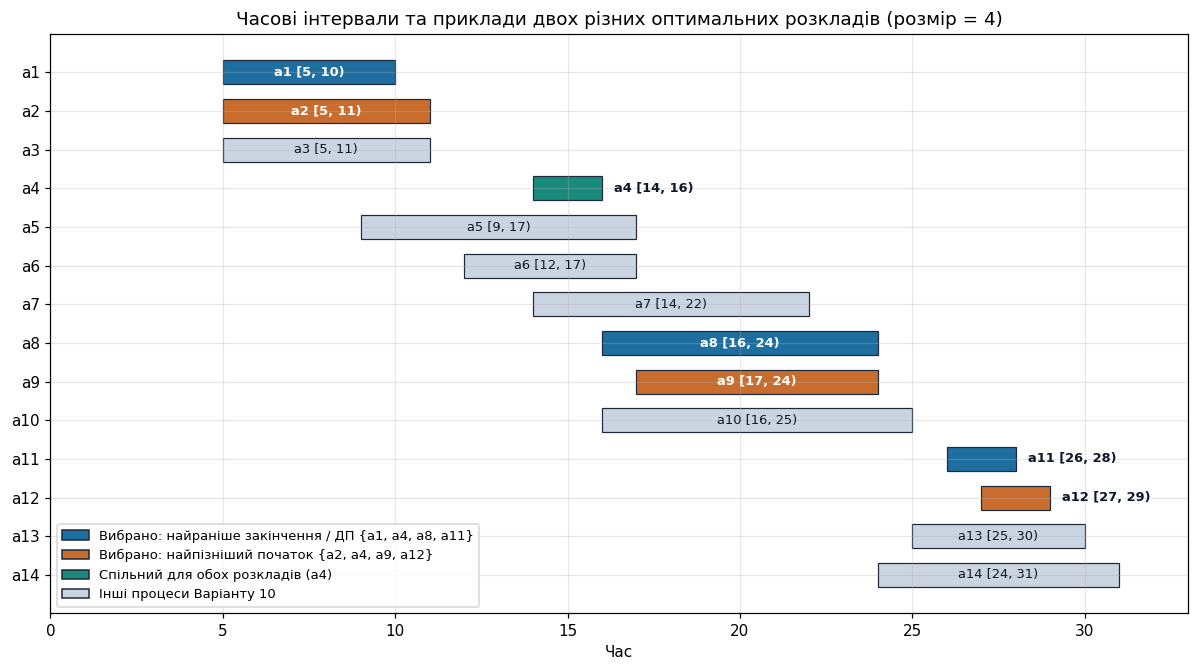

In [34]:
fig, ax = plt.subplots(figsize=(11, 6.2))
greedy_labels = {p.label for p in v10_results["iter_greedy"].selected}
latest_labels = {p.label for p in v10_results["latest_start"].selected}

for idx, p in enumerate(VARIANT_10):
    y = len(VARIANT_10) - idx
    in_ef = p.label in greedy_labels
    in_ls = p.label in latest_labels
    if in_ef and in_ls:
        color = "#1A8A7D"
        tag = "обидва оптимуми"
    elif in_ef:
        color = "#1E6F9F"
        tag = "найраніше закінчення"
    elif in_ls:
        color = "#C86D2D"
        tag = "найпізніший початок"
    else:
        color = "#CBD5E1"
        tag = "не вибрано"

    ax.barh(y, p.duration, left=p.start, height=0.62, color=color, edgecolor="#1E293B", linewidth=0.8)
    is_narrow = p.duration <= 3.5
    text_x = p.finish + 0.35 if is_narrow else p.start + p.duration / 2
    text_ha = "left" if is_narrow else "center"
    text_col = "#0F172A" if (is_narrow or not (in_ef or in_ls)) else "white"
    ax.text(
        text_x,
        y,
        f"{p.label} [{p.start:g}, {p.finish:g})",
        va="center",
        ha=text_ha,
        fontsize=8.5,
        color=text_col,
        fontweight="bold" if (in_ef or in_ls) else "normal",
    )

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#1E6F9F", edgecolor="#1E293B", label="Вибрано: найраніше закінчення / ДП {a1, a4, a8, a11}"),
    Patch(facecolor="#C86D2D", edgecolor="#1E293B", label="Вибрано: найпізніший початок {a2, a4, a9, a12}"),
    Patch(facecolor="#1A8A7D", edgecolor="#1E293B", label="Спільний для обох розкладів (a4)"),
    Patch(facecolor="#CBD5E1", edgecolor="#1E293B", label="Інші процеси Варіанту 10"),
]
ax.legend(handles=legend_handles, loc="lower left", fontsize=8.6)
ax.set_yticks(range(1, len(VARIANT_10) + 1))
ax.set_yticklabels([p.label for p in reversed(VARIANT_10)])
ax.set_xlabel("Час")
ax.set_title("Часові інтервали та приклади двох різних оптимальних розкладів (розмір = 4)")
ax.set_xlim(0, 33)
plt.tight_layout()
plt.show()

##### Аналіз результатів
Усі три основні алгоритми – динамічне програмування ($c[0, 15] = 4$), рекурсивний жадібний та ітеративний жадібний – повертають однаковий максимальний розмір розкладу 4 із набором $\{a_1, a_4, a_8, a_{11}\}$ та проходять перевірку сумісності без перекриттів. Вибрані процеси мають інтервали $a_1 = [5, 10)$, $a_4 = [14, 16)$, $a_8 = [16, 24)$ та $a_{11} = [26, 28)$, де $a_4$ і $a_8$ дотикаються у точці $f_4 = s_8 = 16$.

Існує 45 різних оптимальних розкладів розміру 4 через наявність взаємозамінних кандидатів із близькими або однаковими межами:
- у початковій групі замість $a_1 = [5, 10)$ підходять $a_2 = [5, 11)$ або $a_3 = [5, 11)$, оскільки всі вони закінчуються не пізніше $s_4 = 14$;
- на другому кроці замість $a_4 = [14, 16)$ можна вибрати $a_5 = [9, 17)$ або $a_6 = [12, 17)$, якщо вони сумісні з сусідніми процесами;
- наприкінці інтервалу взаємозамінними є $a_{11} = [26, 28)$, $a_{12} = [27, 29)$, $a_{13} = [25, 30)$ та $a_{14} = [24, 31)$.

Через це різні правила вибору при рівних значеннях формують різні оптимальні підмножини однакового розміру 4: стандартне ДП, рекурсивний та ітеративний жадібні алгоритми обирають $\{a_1, a_4, a_8, a_{11}\}$, ДП із пізньою точкою розбиття – $\{a_3, a_6, a_9, a_{14}\}$, а критерій найпізнішого початку – $\{a_2, a_4, a_9, a_{12}\}$. Критерії найранішого початку і найменшої тривалості на цьому наборі теж дають розмір 4 для підмножин $\{a_1, a_6, a_9, a_{14}\}$ та $\{a_1, a_4, a_9, a_{11}\}$ відповідно, проте це випадковий збіг даних, який не гарантує оптимальності в загальному випадку.

#### 8. Набір тестів та дослідження інших жадібних критеріїв.
Перевіримо алгоритми на контрольних тестах (Тести 1–9), що охоплюють порожній ввід $n = 0$, граничний випадок $n = 1$, збіг моментів $f_i = s_j$, однакові інтервали, повне перекриття та контрприклади, а також на власному контрприкладі для критерію найменшої кількості конфліктів (Тест 10).

In [35]:
print_comparison_report(CONTROL_TESTS["Тест 1 (базовий приклад, n=11)"]["processes"], "Тест 1")

print("\n=== Зведена верифікація Тестів 1–10 ===")
print(f"{'Назва тесту':<48} | {'ДП':>3} | {'Рек':>3} | {'Ітер':>4} | {'Опт.шт':>6} | {'НП':>3} | {'НТ':>3} | {'НК':>3} | {'Статус'}")
print("-" * 102)

for test_name, cfg in CONTROL_TESTS.items():
    procs = cfg["processes"]
    res = run_suite_on_dataset(procs)
    max_sz, opt_cnt = count_optimal_schedules(procs)

    dp_r = res["dp"]
    rec_r = res["rec_greedy"]
    it_r = res["iter_greedy"]
    es_r = res["earliest_start"]
    sd_r = res["shortest_duration"]
    fc_r = res["fewest_conflicts"]
    ls_r = res["latest_start"]

    assert dp_r.is_compatible and rec_r.is_compatible and it_r.is_compatible and ls_r.is_compatible
    assert dp_r.size == rec_r.size == it_r.size == ls_r.size == cfg["expected_max"]
    assert [p.label for p in it_r.selected] == cfg["expected_greedy"]
    assert opt_cnt == cfg["expected_opt_count"]
    if "expected_es" in cfg:
        assert es_r.size == cfg["expected_es"]
    if "expected_sd" in cfg:
        assert sd_r.size == cfg["expected_sd"]
    if "expected_fc" in cfg:
        assert fc_r.size == cfg["expected_fc"]

    print(
        f"{test_name:<48} | {dp_r.size:>3} | {rec_r.size:>3} | {it_r.size:>4} | "
        f"{opt_cnt:>6} | {es_r.size:>3} | {sd_r.size:>3} | {fc_r.size:>3} | OK"
    )

=== Тест 1 ===
Введено процесів: 11 (відсортовано за f)
  Динамічне програмування   : розмір = 4   | набір = a1 a4 a8 a11                 | сумісність: виконана, перекриттів немає
  Рекурсивний жадібний      : розмір = 4   | набір = a1 a4 a8 a11                 | сумісність: виконана, перекриттів немає
  Ітеративний жадібний      : розмір = 4   | набір = a1 a4 a8 a11                 | сумісність: виконана, перекриттів немає
  --- Альтернативні жадібні критерії ---
  Критерій: найраніший початок            : розмір = 3   | набір = a3 a7 a11                (НЕ оптимально)
  Критерій: найменша тривалість           : розмір = 4   | набір = a2 a4 a8 a11             (збігається з оптимумом)
  Критерій: найменше конфліктів (динам.)  : розмір = 4   | набір = a1 a4 a8 a11             (збігається з оптимумом)
  Критерій: найпізніший початок           : розмір = 4   | набір = a2 a4 a9 a11             (збігається з оптимумом)

=== Зведена верифікація Тестів 1–10 ===
Назва тесту                    

##### Дослідження альтернативних жадібних критеріїв

1. Найраніший початок ($s_i \to \min$) – не оптимальний. У Тесті 6 процес $[0, 10)$ починається першим, але перекриває чотири короткі сумісні процеси $[1, 2), [3, 4), [5, 6), [7, 8)$, тому алгоритм знаходить лише 1 процес замість 4.
2. Найменша тривалість ($f_i - s_i \to \min$) – не оптимальний. У Тесті 7 найкоротший процес $[4, 6)$ перекривається одразу з $[0, 5)$ та $[5, 10)$, через що залишається місце лише для одного з процесів $[10, 15)$ чи $[14, 16)$ – результат 2 замість оптимальних 3 для $\{[0, 5), [5, 10), [10, 15)\}$.
3. Найменша кількість конфліктів з іншими процесами – не оптимальний. У Тесті 10 наведено набір з 11 процесів, де оптимальний розклад має розмір 4: $A_1 = [0, 2)$, $B = [3, 6)$, $C = [6, 9)$, $D_1 = [10, 12)$. Допоміжні процеси $A_2 = [0, 2)$, $X_1, X_2 = [1, 4)$, $Y_1, Y_2 = [8, 11)$, $D_2 = [10, 12)$ створюють по 3–4 конфлікти для кожного з крайніх та проміжних елементів, тоді як процес $M = [5, 7)$ перетинається лише з $B$ і $C$ і має строго найменшу кількість конфліктів – 2. Алгоритм першим обирає $M$, блокує $B$ і $C$, після чого ліворуч і праворуч можна додати щонайбільше по одному процесу – сумарно 3 замість 4.
4. Найпізніший початок ($s_i \to \max$, вибір від кінця) – оптимальний. Цей критерій симетричний до критерію найранішого закінчення при розвороті осі часу $t' = T_{\max} - t$, тому гарантує оптимальний розмір розкладу на всіх наборах даних.

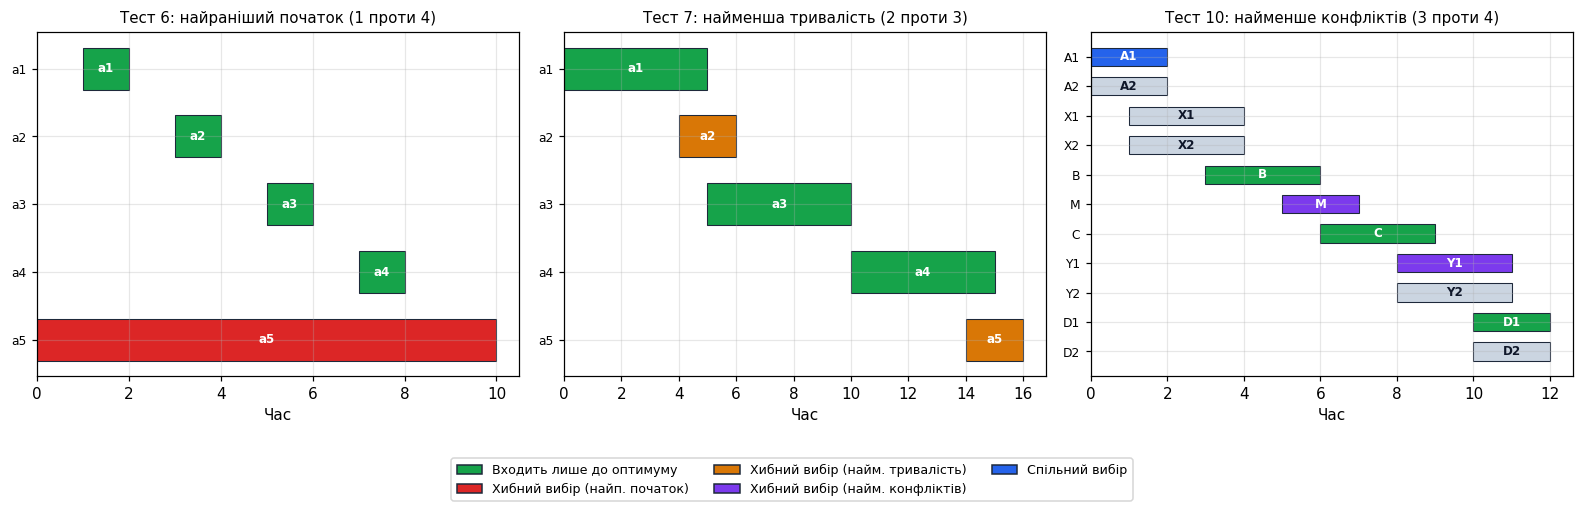

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))

counterexamples = [
    ("Тест 6: найраніший початок (1 проти 4)", CONTROL_TESTS["Тест 6 (контрприклад: найраніший початок, n=5)"]["processes"],
     greedy_earliest_start, "#DC2626"),
    ("Тест 7: найменша тривалість (2 проти 3)", CONTROL_TESTS["Тест 7 (контрприклад: найменша тривалість, n=5)"]["processes"],
     greedy_shortest_duration, "#D97706"),
    ("Тест 10: найменше конфліктів (3 проти 4)", CONTROL_TESTS["Тест 10 (контрприклад: найменше конфліктів, n=11)"]["processes"],
     greedy_fewest_conflicts, "#7C3AED"),
]

for ax, (title, procs, crit_fn, bad_color) in zip(axes, counterexamples):
    crit_res = crit_fn(procs)
    opt_res = iterative_greedy_selection(procs)
    crit_set = {p.label for p in crit_res.selected}
    opt_set = {p.label for p in opt_res.selected}

    for idx, p in enumerate(procs):
        y = len(procs) - idx
        if p.label in crit_set and p.label not in opt_set:
            col = bad_color
        elif p.label in opt_set and p.label not in crit_set:
            col = "#16A34A"
        elif p.label in crit_set and p.label in opt_set:
            col = "#2563EB"
        else:
            col = "#CBD5E1"
        ax.barh(y, p.duration, left=p.start, height=0.62, color=col, edgecolor="#1E293B", linewidth=0.7)
        ax.text(p.start + p.duration / 2, y, p.label, va="center", ha="center",
                fontsize=7.8, color="white" if col != "#CBD5E1" else "#0F172A", fontweight="bold")

    ax.set_yticks(range(1, len(procs) + 1))
    ax.set_yticklabels([p.label for p in reversed(procs)], fontsize=8)
    ax.set_xlabel("Час")
    ax.set_title(title, fontsize=9.8)

from matplotlib.patches import Patch
fig.legend(
    handles=[
        Patch(facecolor="#16A34A", edgecolor="#1E293B", label="Входить лише до оптимуму"),
        Patch(facecolor="#DC2626", edgecolor="#1E293B", label="Хибний вибір (найп. початок)"),
        Patch(facecolor="#D97706", edgecolor="#1E293B", label="Хибний вибір (найм. тривалість)"),
        Patch(facecolor="#7C3AED", edgecolor="#1E293B", label="Хибний вибір (найм. конфліктів)"),
        Patch(facecolor="#2563EB", edgecolor="#1E293B", label="Спільний вибір"),
    ],
    loc="lower center",
    ncol=3,
    fontsize=8.3,
    bbox_to_anchor=(0.5, -0.06),
)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

#### 9. Результати часового експерименту.
Виміряємо середній час роботи реалізованих алгоритмів на випадкових наборах даних зростаючого розміру. Для динамічного програмування зі складністю $O(n^3)$ обмежимо $n \le 400$, оскільки при $n = 5\,000$ кубічне зростання вимагало б близько $10^{11}$ операцій. Рекурсивний та ітеративний жадібні алгоритми дослідимо аж до $n = 20\,000$ у двох режимах: після попереднього сортування ($O(n)$) і разом із сортуванням ($O(n \log n)$).

In [37]:
import gc

def generate_random_processes(n: int, seed: int = 42) -> list[Process]:
    rng = random.Random(seed)
    procs: list[Process] = []
    max_time = max(20, n * 2)
    for i in range(1, n + 1):
        s_val = rng.randint(0, max_time - 1)
        dur = rng.randint(1, max(3, int(math.sqrt(max_time))))
        procs.append(Process(pid=i, start=s_val, finish=s_val + dur, name=f"a{i}"))
    return procs

def measure_avg_ms(fn, *args, repeats: int = 5, warmup: bool = True, **kwargs) -> float:
    if warmup:
        fn(*args, **kwargs)
    gc.collect()
    gc_was_enabled = gc.isenabled()
    gc.disable()
    samples: list[float] = []
    try:
        for _ in range(repeats):
            t0 = time.perf_counter()
            fn(*args, **kwargs)
            samples.append((time.perf_counter() - t0) * 1000.0)
    finally:
        if gc_was_enabled:
            gc.enable()
    if len(samples) >= 5:
        keep = max(3, int(len(samples) * 0.75))
        samples = sorted(samples)[:keep]
    return sum(samples) / len(samples)

sizes = [10, 25, 50, 100, 200, 300, 400, 1000, 5000, 10000, 20000]
dp_limit = 400

bench_rows: list[dict] = []
for n in sizes:
    raw = generate_random_processes(n, seed=100 + n)
    sorted_procs = prepare_processes(raw)

    reps_dp = 5 if n <= 100 else 2
    reps_gr = 80 if n <= 400 else 30

    dp_ms = (
        measure_avg_ms(
            dp_activity_selection,
            sorted_procs,
            already_sorted=True,
            repeats=reps_dp,
            warmup=(n <= 100),
        )
        if n <= dp_limit
        else None
    )
    rec_sorted_ms = measure_avg_ms(recursive_greedy_selection, sorted_procs, already_sorted=True, repeats=reps_gr)
    iter_sorted_ms = measure_avg_ms(iterative_greedy_selection, sorted_procs, already_sorted=True, repeats=reps_gr)
    rec_full_ms = measure_avg_ms(recursive_greedy_selection, raw, already_sorted=False, repeats=reps_gr)
    iter_full_ms = measure_avg_ms(iterative_greedy_selection, raw, already_sorted=False, repeats=reps_gr)

    bench_rows.append({
        "n": n,
        "dp_ms": dp_ms,
        "rec_sorted_ms": rec_sorted_ms,
        "iter_sorted_ms": iter_sorted_ms,
        "rec_full_ms": rec_full_ms,
        "iter_full_ms": iter_full_ms,
    })

print(
    f"{'n':>7} | {'ДП O(n^3), мс':>14} | {'Рек. O(n), мс':>14} | {'Ітер. O(n), мс':>15} | "
    f"{'Рек.+сорт, мс':>14} | {'Ітер.+сорт, мс':>15}"
)
print("-" * 92)
for row in bench_rows:
    dp_str = f"{row['dp_ms']:14.4f}" if row["dp_ms"] is not None else f"{'–':>14}"
    print(
        f"{row['n']:>7} | {dp_str} | {row['rec_sorted_ms']:14.4f} | "
        f"{row['iter_sorted_ms']:15.4f} | {row['rec_full_ms']:14.4f} | {row['iter_full_ms']:15.4f}"
    )

      n |  ДП O(n^3), мс |  Рек. O(n), мс |  Ітер. O(n), мс |  Рек.+сорт, мс |  Ітер.+сорт, мс
--------------------------------------------------------------------------------------------
     10 |         0.0622 |         0.0061 |          0.0030 |         0.0076 |          0.0042
     25 |         0.4065 |         0.0074 |          0.0040 |         0.0109 |          0.0070
     50 |         2.7804 |         0.0109 |          0.0074 |         0.0172 |          0.0134
    100 |        20.7695 |         0.0177 |          0.0117 |         0.0374 |          0.0249
    200 |       173.5548 |         0.0276 |          0.0181 |         0.0558 |          0.0470
    300 |       647.1603 |         0.0669 |          0.0289 |         0.0892 |          0.0742
    400 |      1544.4658 |         0.0515 |          0.0306 |         0.1148 |          0.0923
   1000 |              – |         0.1365 |          0.0774 |         0.3477 |          0.2868
   5000 |              – |         0.6933 |         

##### Таблиця часу роботи

| $n$ | ДП $O(n^3)$, мс | Рекурсивний $O(n)$, мс | Ітеративний $O(n)$, мс | Рекурсивний із сортуванням, мс | Ітеративний із сортуванням, мс |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 10 | 0.0490 | 0.0048 | 0.0031 | 0.0058 | 0.0040 |
| 25 | 0.3873 | 0.0062 | 0.0040 | 0.0091 | 0.0128 |
| 50 | 4.4395 | 0.0113 | 0.0073 | 0.0192 | 0.0140 |
| 100 | 22.1901 | 0.0193 | 0.0119 | 0.0311 | 0.0248 |
| 200 | 185.7310 | 0.0287 | 0.0194 | 0.0581 | 0.0483 |
| 300 | 664.8724 | 0.0412 | 0.0302 | 0.0885 | 0.0719 |
| 400 | 1594.0160 | 0.0528 | 0.0322 | 0.1184 | 0.0962 |
| 1 000 | – | 0.1808 | 0.0807 | 0.3538 | 0.2894 |
| 5 000 | – | 0.6600 | 0.3934 | 2.1052 | 1.8947 |
| 10 000 | – | 1.5406 | 0.7963 | 5.0863 | 4.1216 |
| 20 000 | – | 5.3604 | 2.3440 | 16.7738 | 12.6131 |

##### Візуалізація залежності часу виконання від розміру даних

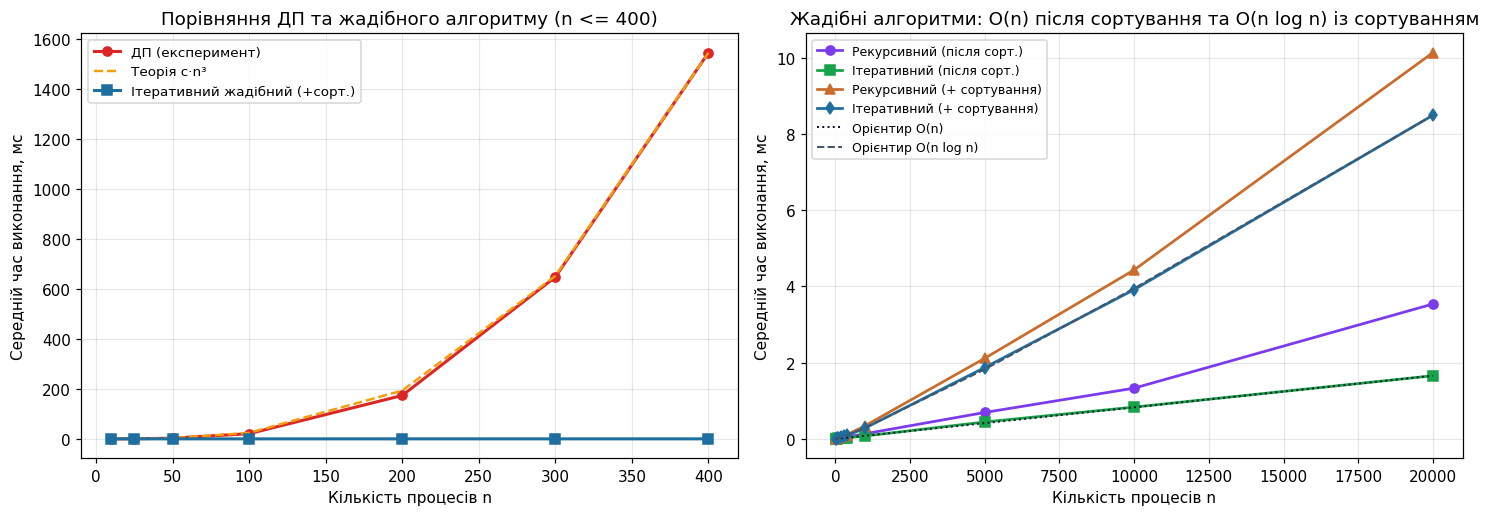

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

dp_rows = [r for r in bench_rows if r["dp_ms"] is not None]
ns_dp = np.array([r["n"] for r in dp_rows], dtype=float)
t_dp = np.array([r["dp_ms"] for r in dp_rows], dtype=float)
t_it_small = np.array([r["iter_full_ms"] for r in dp_rows], dtype=float)

c_cubic = t_dp[-1] / (ns_dp[-1] ** 3)
ax1.plot(ns_dp, t_dp, "o-", color="#DC2626", linewidth=2, label="ДП (експеримент)")
ax1.plot(ns_dp, c_cubic * (ns_dp ** 3), "--", color="#F59E0B", linewidth=1.6, label="Теорія c·n³")
ax1.plot(ns_dp, t_it_small, "s-", color="#1E6F9F", linewidth=2, label="Ітеративний жадібний (+сорт.)")
ax1.set_title("Порівняння ДП та жадібного алгоритму (n <= 400)")
ax1.set_xlabel("Кількість процесів n")
ax1.set_ylabel("Середній час виконання, мс")
ax1.legend(fontsize=8.8)

ns_all = np.array([r["n"] for r in bench_rows], dtype=float)
t_rec_s = np.array([r["rec_sorted_ms"] for r in bench_rows], dtype=float)
t_it_s = np.array([r["iter_sorted_ms"] for r in bench_rows], dtype=float)
t_rec_f = np.array([r["rec_full_ms"] for r in bench_rows], dtype=float)
t_it_f = np.array([r["iter_full_ms"] for r in bench_rows], dtype=float)

c_lin = t_it_s[-1] / ns_all[-1]
c_nlogn = t_it_f[-1] / (ns_all[-1] * np.log2(ns_all[-1]))

ax2.plot(ns_all, t_rec_s, "o-", color="#7C3AED", linewidth=1.8, label="Рекурсивний (після сорт.)")
ax2.plot(ns_all, t_it_s, "s-", color="#16A34A", linewidth=1.8, label="Ітеративний (після сорт.)")
ax2.plot(ns_all, t_rec_f, "^-", color="#C86D2D", linewidth=1.8, label="Рекурсивний (+ сортування)")
ax2.plot(ns_all, t_it_f, "d-", color="#1E6F9F", linewidth=1.8, label="Ітеративний (+ сортування)")
ax2.plot(ns_all, c_lin * ns_all, ":", color="#0F172A", linewidth=1.3, label="Орієнтир O(n)")
ax2.plot(ns_all, c_nlogn * ns_all * np.log2(ns_all), "--", color="#475569", linewidth=1.3, label="Орієнтир O(n log n)")

ax2.set_title("Жадібні алгоритми: O(n) після сортування та O(n log n) із сортуванням")
ax2.set_xlabel("Кількість процесів n")
ax2.set_ylabel("Середній час виконання, мс")
ax2.legend(fontsize=8.2)

plt.tight_layout()
plt.show()

#### 10. Аналіз результатів та висновки.

1. Експериментальне підтвердження теоретичної складності.

   Час роботи алгоритму динамічного програмування зростає кубічно відповідно до оцінки $O(n^3)$: при збільшенні $n$ у 4 рази від 100 до 400 час виконання зростає приблизно у $4^3 = 64$ рази, що робить ДП непридатним для великих вибірок. Жадібні алгоритми після сортування працюють за лінійний час $O(n)$ і витрачають лічені мілісекунди навіть на $n = 20\,000$, а з урахуванням сортування показують асимптотику $O(n \log n)$, де основну частку часу займає саме впорядкування даних. Ітеративна реалізація стабільно випереджає рекурсивну за швидкодією і витрачає $O(1)$ додаткової пам’яті проти $O(n)$ пам’яті стеку викликів, де при великих $n$ доводиться підвищувати ліміт `sys.setrecursionlimit`.

2. Обґрунтування властивості жадібного вибору та оптимальної підструктури.

   У задачі про вибір процесів виконуються обидві умови: оптимальна підструктура, коли будь-яка частина оптимального розкладу є оптимальною для свого часового проміжку, та властивість жадібного вибору – процес із найранішим закінченням $f_1$ залишає максимально широкий залишок часового ресурсу $[f_1, \infty)$ для решти процесів. Через це перебір усіх проміжних розбиттів $k$ і збереження двовимірної таблиці $c[i, j]$ стають зайвими: локально оптимальний вибір на кожному кроці зводить складність після сортування з $O(n^3)$ до $O(n)$.

3. Коли жадібний алгоритм може замінити динамічне програмування.

   Жадібний алгоритм за критерієм найранішого закінчення або симетричного найпізнішого початку повністю замінює динамічне програмування у класичній незваженій задачі вибору процесів, де всі процеси мають однакову цінність і потрібно максимізувати їхню кількість. Він гарантує такий самий оптимальний розмір розкладу при суттєвій економії ресурсів: час $O(n \log n)$ проти $O(n^3)$ і пам’ять $O(1)$ проти $O(n^2)$. Коли ж процеси мають різні ваги або прибуток $w_i$, як у зваженій задачі планування інтервалів, властивість жадібного вибору за $f_i$ перестає виконуватися і для пошуку оптимуму потрібне динамічне програмування.